In [4]:
import gc
import json
import time
from pathlib import Path
import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid")

CWD = Path.cwd()
BASE_DIR = CWD.parent if CWD.name == "analysis" else CWD
RESULT_DIR = BASE_DIR / "results"
FIG_DIR = RESULT_DIR / "figures"
MODEL_DIR = RESULT_DIR / "models"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PARQUET = RESULT_DIR / "step04_02_train_features.parquet"
VAL_PARQUET   = RESULT_DIR / "step04_02_val_features.parquet"
TEST_PARQUET  = RESULT_DIR / "step04_02_test_features.parquet"
PREPROC_JSON  = RESULT_DIR / "step04_02_preprocessing_artifacts.json"

for fp in [TRAIN_PARQUET, VAL_PARQUET, TEST_PARQUET, PREPROC_JSON]:
    assert fp.exists(), f"Missing required Step 4.2 artifact: {fp}"

with open(PREPROC_JSON, "r", encoding="utf-8") as f:
    preproc_meta = json.load(f)

FEATURE_COLS = preproc_meta["feature_columns"]
TARGET_COL   = preproc_meta["target_column"]
SCALER_STATS = preproc_meta["standard_scaler_fit_on_train"]

# Build float32 vectors for training-fitted z-score standardization
TRAIN_MEANS = np.array([SCALER_STATS[c]["mean"] for c in FEATURE_COLS], dtype=np.float32)
TRAIN_STDS  = np.array([SCALER_STATS[c]["std"]  for c in FEATURE_COLS], dtype=np.float32)

def standardize_features(X: np.ndarray) -> np.ndarray:
    return (X - TRAIN_MEANS) / TRAIN_STDS

def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    # Clip predictions to physical domain bounds [-120.0, 1440.0] established in Step 2.3
    y_pred_clipped = np.clip(y_pred, -120.0, 1440.0)
    mae  = float(mean_absolute_error(y_true, y_pred_clipped))
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred_clipped)))
    r2   = float(r2_score(y_true, y_pred_clipped))
    med_ae = float(np.median(np.abs(y_true - y_pred_clipped)))
    bias = float(np.mean(y_pred_clipped - y_true))
    return {
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 6),
        "Median_AE": round(med_ae, 4),
        "Mean_Bias": round(bias, 4),
    }

con = duckdb.connect(database=":memory:")
con.execute("PRAGMA threads=4;")
print(f"Loaded {len(FEATURE_COLS)} feature definitions and training-fitted scaler parameters.")

Loaded 12 feature definitions and training-fitted scaler parameters.


In [5]:
t0 = time.time()
feat_sql_list = ", ".join(FEATURE_COLS)

# 1. Load 100% of Validation partition (3,278,765 rows) as float32
val_df = con.execute(f"""
SELECT
    {feat_sql_list},
    {TARGET_COL},
    primary_type_code,
    is_premium_special,
    target_severity,
    is_terminal_arrival
FROM read_parquet('{VAL_PARQUET.as_posix()}')
""").df()

X_val = val_df[FEATURE_COLS].to_numpy(dtype=np.float32, copy=True)
y_val = val_df[TARGET_COL].to_numpy(dtype=np.float32, copy=True)
val_meta_df = val_df[["primary_type_code", "is_premium_special", "target_severity", "is_terminal_arrival"]].copy()
del val_df
gc.collect()

# 2. Load 100% of untouched Test partition (3,351,989 rows) as float32
test_df = con.execute(f"""
SELECT
    {feat_sql_list},
    {TARGET_COL},
    primary_type_code,
    is_premium_special,
    target_severity,
    is_terminal_arrival
FROM read_parquet('{TEST_PARQUET.as_posix()}')
""").df()

X_test = test_df[FEATURE_COLS].to_numpy(dtype=np.float32, copy=True)
y_test = test_df[TARGET_COL].to_numpy(dtype=np.float32, copy=True)
test_meta_df = test_df[["primary_type_code", "is_premium_special", "target_severity", "is_terminal_arrival"]].copy()
del test_df
gc.collect()

# 3. Extract reproducible 2,500,000-row training sample for Linear Regression & XGBoost
#    and 600,000-row subset for Random Forest Regressor (preventing unnecessary 26.5M-row RAM exhaustion)
N_TRAIN_SAMPLE = 2_500_000
N_RF_SAMPLE    = 600_000

train_sample_df = con.execute(f"""
SELECT
    {feat_sql_list},
    {TARGET_COL}
FROM read_parquet('{TRAIN_PARQUET.as_posix()}')
USING SAMPLE reservoir({N_TRAIN_SAMPLE} ROWS) REPEATABLE (42);
""").df()

X_train_sample = train_sample_df[FEATURE_COLS].to_numpy(dtype=np.float32, copy=True)
y_train_sample = train_sample_df[TARGET_COL].to_numpy(dtype=np.float32, copy=True)
del train_sample_df
gc.collect()

rng = np.random.default_rng(42)
rf_idx = rng.choice(len(X_train_sample), size=N_RF_SAMPLE, replace=False)
X_train_rf = X_train_sample[rf_idx]
y_train_rf = y_train_sample[rf_idx]

print(f"Data loaded in {time.time() - t0:.2f}s:")
print(f"  X_train_sample (Linear/XGB) : {X_train_sample.shape} ({X_train_sample.nbytes / 1e6:.1f} MB)")
print(f"  X_train_rf     (RandomForest): {X_train_rf.shape} ({X_train_rf.nbytes / 1e6:.1f} MB)")
print(f"  X_val          (100% Full)  : {X_val.shape} ({X_val.nbytes / 1e6:.1f} MB)")
print(f"  X_test         (100% Full)  : {X_test.shape} ({X_test.nbytes / 1e6:.1f} MB)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Data loaded in 75.47s:
  X_train_sample (Linear/XGB) : (2500000, 12) (120.0 MB)
  X_train_rf     (RandomForest): (600000, 12) (28.8 MB)
  X_val          (100% Full)  : (3278765, 12) (157.4 MB)
  X_test         (100% Full)  : (3351989, 12) (160.9 MB)


In [6]:
tuning_records = []
val_predictions = {}
test_predictions = {}

# ==============================================================================
# MODEL 1: PERSISTENCE BASELINE (y_hat = curr_delay_min)
# ==============================================================================
t_m1 = time.time()

# Out-of-core exact training metrics on all 26,528,080 training transitions
persist_train_sql = con.execute(f"""
SELECT
    ROUND(AVG(ABS(target_next_delay_min - curr_delay_min)), 4) AS MAE,
    ROUND(SQRT(AVG(POWER(target_next_delay_min - curr_delay_min, 2))), 4) AS RMSE,
    ROUND(1.0 - SUM(POWER(target_next_delay_min - curr_delay_min, 2))
              / SUM(POWER(target_next_delay_min - {SCALER_STATS['curr_delay_min']['mean']}, 2)), 6) AS R2_approx,
    ROUND(MEDIAN(ABS(target_next_delay_min - curr_delay_min)), 4) AS Median_AE,
    ROUND(AVG(curr_delay_min - target_next_delay_min), 4) AS Mean_Bias
FROM read_parquet('{TRAIN_PARQUET.as_posix()}');
""").df().iloc[0].to_dict()

y_val_persist  = X_val[:, 0].copy()   # curr_delay_min is index 0
y_test_persist = X_test[:, 0].copy()

val_metrics_persist  = compute_metrics(y_val, y_val_persist)
test_metrics_persist = compute_metrics(y_test, y_test_persist)
train_sample_metrics_persist = compute_metrics(y_train_sample, X_train_sample[:, 0])

val_predictions["1_Persistence_Baseline"]  = y_val_persist
test_predictions["1_Persistence_Baseline"] = y_test_persist

tuning_records.append({
    "model_family": "1_Persistence_Baseline",
    "config_id": "identity_curr_delay",
    "hyperparameters": "y_hat = curr_delay_min (no free parameters)",
    "train_sample_MAE": train_sample_metrics_persist["MAE"],
    "train_sample_RMSE": train_sample_metrics_persist["RMSE"],
    "train_sample_R2": train_sample_metrics_persist["R2"],
    "val_MAE": val_metrics_persist["MAE"],
    "val_RMSE": val_metrics_persist["RMSE"],
    "val_R2": val_metrics_persist["R2"],
    "fit_time_sec": round(time.time() - t_m1, 2),
    "is_selected": True,
})
print("=== MODEL 1: PERSISTENCE BASELINE ===")
print(f"  Full 26.53M Train MAE: {persist_train_sql['MAE']:.4f} | RMSE: {persist_train_sql['RMSE']:.4f}")
print(f"  Validation (3.28M)    : {val_metrics_persist}")

# ==============================================================================
# MODEL 2: LINEAR REGRESSION (OLS & RIDGE L2 TUNING ON STANDARDIZED FEATURES)
# ==============================================================================
print("\n=== MODEL 2: LINEAR REGRESSION (STANDARDIZED FEATURES) ===")
X_train_std = standardize_features(X_train_sample)
X_val_std   = standardize_features(X_val)
X_test_std  = standardize_features(X_test)

best_lin_val_rmse = float("inf")
best_lin_model = None
best_lin_cfg = None

for alpha_val in [0.0, 10.0, 1000.0]:
    t_s = time.time()
    if alpha_val == 0.0:
        model_lin = LinearRegression()
        cfg_name = "OLS (alpha=0.0)"
    else:
        model_lin = Ridge(alpha=alpha_val, random_state=42)
        cfg_name = f"Ridge (alpha={alpha_val})"
    model_lin.fit(X_train_std, y_train_sample)
    fit_sec = round(time.time() - t_s, 2)

    tr_m  = compute_metrics(y_train_sample, model_lin.predict(X_train_std))
    val_m = compute_metrics(y_val, model_lin.predict(X_val_std))
    is_best = val_m["RMSE"] < best_lin_val_rmse
    if is_best:
        best_lin_val_rmse = val_m["RMSE"]
        best_lin_model = model_lin
        best_lin_cfg = cfg_name

    tuning_records.append({
        "model_family": "2_Linear_Regression",
        "config_id": cfg_name,
        "hyperparameters": f"alpha={alpha_val}, standardized=True",
        "train_sample_MAE": tr_m["MAE"],
        "train_sample_RMSE": tr_m["RMSE"],
        "train_sample_R2": tr_m["R2"],
        "val_MAE": val_m["MAE"],
        "val_RMSE": val_m["RMSE"],
        "val_R2": val_m["R2"],
        "fit_time_sec": fit_sec,
        "is_selected": False,
    })
    print(f"  [{cfg_name:18s}] Val MAE={val_m['MAE']:.4f} | Val RMSE={val_m['RMSE']:.4f} | Val R2={val_m['R2']:.6f} ({fit_sec}s)")

# Mark selected Linear Regression configuration
for r in tuning_records:
    if r["model_family"] == "2_Linear_Regression" and r["config_id"] == best_lin_cfg:
        r["is_selected"] = True

val_predictions["2_Linear_Regression"]  = np.clip(best_lin_model.predict(X_val_std), -120.0, 1440.0)
test_predictions["2_Linear_Regression"] = np.clip(best_lin_model.predict(X_test_std), -120.0, 1440.0)
joblib.dump(best_lin_model, MODEL_DIR / "step04_03_linear_regression.joblib")

del X_train_std, X_val_std, X_test_std
gc.collect()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== MODEL 1: PERSISTENCE BASELINE ===
  Full 26.53M Train MAE: 7.5710 | RMSE: 18.0731
  Validation (3.28M)    : {'MAE': 8.4207, 'RMSE': 20.3487, 'R2': 0.935176, 'Median_AE': 3.0, 'Mean_Bias': -1.3907}

=== MODEL 2: LINEAR REGRESSION (STANDARDIZED FEATURES) ===
  [OLS (alpha=0.0)   ] Val MAE=7.2529 | Val RMSE=17.9557 | Val R2=0.949526 (0.62s)
  [Ridge (alpha=10.0)] Val MAE=7.1502 | Val RMSE=17.8032 | Val R2=0.950380 (0.29s)
  [Ridge (alpha=1000.0)] Val MAE=7.1508 | Val RMSE=17.8043 | Val R2=0.950374 (0.26s)


0

In [7]:
# ==============================================================================
# MODEL 3: RANDOM FOREST REGRESSOR (LIMITED JUSTIFIED TUNING)
# ==============================================================================
print("=== MODEL 3: RANDOM FOREST REGRESSOR ===")
rf_candidates = [
    {"n_estimators": 80, "max_depth": 10, "min_samples_leaf": 50, "max_features": 0.7, "max_samples": 0.5},
    {"n_estimators": 80, "max_depth": 12, "min_samples_leaf": 30, "max_features": 0.7, "max_samples": 0.5},
    {"n_estimators": 80, "max_depth": 14, "min_samples_leaf": 20, "max_features": 0.7, "max_samples": 0.5},
]

best_rf_val_rmse = float("inf")
best_rf_model = None
best_rf_cfg_id = None

for cfg in rf_candidates:
    t_s = time.time()
    cfg_id = f"RF_d{cfg['max_depth']}_leaf{cfg['min_samples_leaf']}"
    rf_model = RandomForestRegressor(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        min_samples_leaf=cfg["min_samples_leaf"],
        max_features=cfg["max_features"],
        max_samples=cfg["max_samples"],
        n_jobs=-1,
        random_state=42,
    )
    rf_model.fit(X_train_rf, y_train_rf)
    fit_sec = round(time.time() - t_s, 2)

    tr_m  = compute_metrics(y_train_rf, rf_model.predict(X_train_rf))
    val_m = compute_metrics(y_val, rf_model.predict(X_val))

    if val_m["RMSE"] < best_rf_val_rmse:
        best_rf_val_rmse = val_m["RMSE"]
        best_rf_model = rf_model
        best_rf_cfg_id = cfg_id

    tuning_records.append({
        "model_family": "3_Random_Forest",
        "config_id": cfg_id,
        "hyperparameters": json.dumps(cfg),
        "train_sample_MAE": tr_m["MAE"],
        "train_sample_RMSE": tr_m["RMSE"],
        "train_sample_R2": tr_m["R2"],
        "val_MAE": val_m["MAE"],
        "val_RMSE": val_m["RMSE"],
        "val_R2": val_m["R2"],
        "fit_time_sec": fit_sec,
        "is_selected": False,
    })
    print(f"  [{cfg_id:16s}] Val MAE={val_m['MAE']:.4f} | Val RMSE={val_m['RMSE']:.4f} | Val R2={val_m['R2']:.6f} ({fit_sec}s)")

for r in tuning_records:
    if r["model_family"] == "3_Random_Forest" and r["config_id"] == best_rf_cfg_id:
        r["is_selected"] = True

val_predictions["3_Random_Forest"]  = np.clip(best_rf_model.predict(X_val), -120.0, 1440.0)
test_predictions["3_Random_Forest"] = np.clip(best_rf_model.predict(X_test), -120.0, 1440.0)
joblib.dump(best_rf_model, MODEL_DIR / "step04_03_random_forest.joblib")

# ==============================================================================
# MODEL 4: XGBOOST REGRESSOR (HISTOGRAM GBDT + EARLY STOPPING TUNING)
# ==============================================================================
print("\n=== MODEL 4: XGBOOST REGRESSOR ===")
xgb_candidates = [
    {"n_estimators": 300, "max_depth": 6,  "learning_rate": 0.08, "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 50},
    {"n_estimators": 300, "max_depth": 8,  "learning_rate": 0.08, "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 50},
    {"n_estimators": 350, "max_depth": 10, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 100},
]

best_xgb_val_rmse = float("inf")
best_xgb_model = None
best_xgb_cfg_id = None

# Use a deterministic 400k validation slice for fast early-stopping monitoring, then evaluate on full 3.28M X_val
val_es_idx = rng.choice(len(X_val), size=400_000, replace=False)
X_val_es, y_val_es = X_val[val_es_idx], y_val[val_es_idx]

for cfg in xgb_candidates:
    t_s = time.time()
    cfg_id = f"XGB_d{cfg['max_depth']}_lr{cfg['learning_rate']}"
    xgb_model = XGBRegressor(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],
        subsample=cfg["subsample"],
        colsample_bytree=cfg["colsample_bytree"],
        min_child_weight=cfg["min_child_weight"],
        reg_alpha=1.0,
        reg_lambda=5.0,
        tree_method="hist",
        early_stopping_rounds=20,
        eval_metric="rmse",
        n_jobs=-1,
        random_state=42,
    )
    xgb_model.fit(
        X_train_sample, y_train_sample,
        eval_set=[(X_val_es, y_val_es)],
        verbose=False,
    )
    fit_sec = round(time.time() - t_s, 2)

    tr_m  = compute_metrics(y_train_sample, xgb_model.predict(X_train_sample))
    val_m = compute_metrics(y_val, xgb_model.predict(X_val))

    if val_m["RMSE"] < best_xgb_val_rmse:
        best_xgb_val_rmse = val_m["RMSE"]
        best_xgb_model = xgb_model
        best_xgb_cfg_id = cfg_id

    tuning_records.append({
        "model_family": "4_XGBoost",
        "config_id": cfg_id,
        "hyperparameters": json.dumps({**cfg, "best_iteration": int(getattr(xgb_model, "best_iteration", cfg["n_estimators"]))}),
        "train_sample_MAE": tr_m["MAE"],
        "train_sample_RMSE": tr_m["RMSE"],
        "train_sample_R2": tr_m["R2"],
        "val_MAE": val_m["MAE"],
        "val_RMSE": val_m["RMSE"],
        "val_R2": val_m["R2"],
        "fit_time_sec": fit_sec,
        "is_selected": False,
    })
    print(f"  [{cfg_id:16s}] Val MAE={val_m['MAE']:.4f} | Val RMSE={val_m['RMSE']:.4f} | Val R2={val_m['R2']:.6f} ({fit_sec}s)")

for r in tuning_records:
    if r["model_family"] == "4_XGBoost" and r["config_id"] == best_xgb_cfg_id:
        r["is_selected"] = True

val_predictions["4_XGBoost"]  = np.clip(best_xgb_model.predict(X_val), -120.0, 1440.0)
test_predictions["4_XGBoost"] = np.clip(best_xgb_model.predict(X_test), -120.0, 1440.0)
best_xgb_model.save_model((MODEL_DIR / "step04_03_xgboost.json").as_posix())

tuning_df = pd.DataFrame(tuning_records)
tuning_df.to_csv(RESULT_DIR / "step04_03_hyperparameter_tuning_log.csv", index=False)
print("\n=== HYPERPARAMETER TUNING SUMMARY ===")
print(tuning_df.to_string(index=False))

=== MODEL 3: RANDOM FOREST REGRESSOR ===
  [RF_d10_leaf50   ] Val MAE=6.8474 | Val RMSE=17.7513 | Val R2=0.950669 (78.24s)
  [RF_d12_leaf30   ] Val MAE=6.7152 | Val RMSE=17.4984 | Val R2=0.952064 (85.94s)
  [RF_d14_leaf20   ] Val MAE=6.6395 | Val RMSE=17.3975 | Val R2=0.952615 (89.93s)

=== MODEL 4: XGBOOST REGRESSOR ===
  [XGB_d6_lr0.08   ] Val MAE=7.5334 | Val RMSE=22.5662 | Val R2=0.920278 (86.53s)
  [XGB_d8_lr0.08   ] Val MAE=7.4511 | Val RMSE=22.5195 | Val R2=0.920607 (84.77s)
  [XGB_d10_lr0.05  ] Val MAE=7.3643 | Val RMSE=22.4499 | Val R2=0.921097 (120.09s)

=== HYPERPARAMETER TUNING SUMMARY ===
          model_family            config_id                                                                                                                                          hyperparameters  train_sample_MAE  train_sample_RMSE  train_sample_R2  val_MAE  val_RMSE   val_R2  fit_time_sec  is_selected
1_Persistence_Baseline  identity_curr_delay                                          

In [8]:
# Compare all 4 selected models across Train Sample, Full Validation (3,278,765), and Untouched Test (3,351,989)
overall_comparison_rows = []
persist_test_mae  = compute_metrics(y_test, test_predictions["1_Persistence_Baseline"])["MAE"]
persist_test_rmse = compute_metrics(y_test, test_predictions["1_Persistence_Baseline"])["RMSE"]

for model_key in ["1_Persistence_Baseline", "2_Linear_Regression", "3_Random_Forest", "4_XGBoost"]:
    sel_row = tuning_df[(tuning_df["model_family"] == model_key) & (tuning_df["is_selected"] == True)].iloc[0]
    val_m   = compute_metrics(y_val, val_predictions[model_key])
    test_m  = compute_metrics(y_test, test_predictions[model_key])

    overall_comparison_rows.append({
        "model": model_key,
        "selected_config": sel_row["config_id"],
        "train_MAE": sel_row["train_sample_MAE"],
        "train_RMSE": sel_row["train_sample_RMSE"],
        "train_R2": sel_row["train_sample_R2"],
        "val_MAE": val_m["MAE"],
        "val_RMSE": val_m["RMSE"],
        "val_R2": val_m["R2"],
        "test_MAE": test_m["MAE"],
        "test_RMSE": test_m["RMSE"],
        "test_R2": test_m["R2"],
        "test_Median_AE": test_m["Median_AE"],
        "test_Mean_Bias": test_m["Mean_Bias"],
        "test_MAE_gain_vs_persistence_pct": round((persist_test_mae - test_m["MAE"]) * 100.0 / persist_test_mae, 2),
        "test_RMSE_gain_vs_persistence_pct": round((persist_test_rmse - test_m["RMSE"]) * 100.0 / persist_test_rmse, 2),
    })

overall_comparison_df = pd.DataFrame(overall_comparison_rows)
overall_comparison_df.to_csv(RESULT_DIR / "step04_03_model_comparison_overall.csv", index=False)

print("=== FINAL UNTOUCHED TEST SET EVALUATION (n = 3,351,989 OBSERVED SCHEDULED TRANSITIONS) ===")
print(overall_comparison_df.to_string(index=False))

=== FINAL UNTOUCHED TEST SET EVALUATION (n = 3,351,989 OBSERVED SCHEDULED TRANSITIONS) ===
                 model     selected_config  train_MAE  train_RMSE  train_R2  val_MAE  val_RMSE   val_R2  test_MAE  test_RMSE  test_R2  test_Median_AE  test_Mean_Bias  test_MAE_gain_vs_persistence_pct  test_RMSE_gain_vs_persistence_pct
1_Persistence_Baseline identity_curr_delay     7.5882     18.3577  0.919518   8.4207   20.3487 0.935176    8.2098    20.2024 0.910606          3.0000         -1.2145                              0.00                               0.00
   2_Linear_Regression  Ridge (alpha=10.0)     6.5345     15.8046  0.940347   7.1502   17.8032 0.950380    7.1739    18.0093 0.928961          3.5208         -0.4357                             12.62                              10.86
       3_Random_Forest       RF_d14_leaf20     5.7793     15.2170  0.945273   6.6395   17.3975 0.952615    6.6842    17.5859 0.932263          3.1657         -0.4890                             18.58     

In [9]:
# 1. Stratified Evaluation by Target Delay Severity (normal <=167.65m, high_risk 167.65-233.68m, critical >233.68m)
severity_rows = []
for sev_label in ["normal", "high_risk", "critical"]:
    mask = (test_meta_df["target_severity"] == sev_label).to_numpy()
    n_sub = int(mask.sum())
    if n_sub == 0:
        continue
    y_sub = y_test[mask]
    for model_key in ["1_Persistence_Baseline", "2_Linear_Regression", "3_Random_Forest", "4_XGBoost"]:
        m_sub = compute_metrics(y_sub, test_predictions[model_key][mask])
        severity_rows.append({
            "target_severity": sev_label,
            "n_test_transitions": n_sub,
            "pct_of_test": round(n_sub * 100.0 / len(y_test), 4),
            "actual_mean_delay_min": round(float(np.mean(y_sub)), 2),
            "model": model_key,
            **m_sub,
        })

severity_perf_df = pd.DataFrame(severity_rows)
severity_perf_df.to_csv(RESULT_DIR / "step04_03_test_performance_by_severity.csv", index=False)
print("=== TEST SET PERFORMANCE BY TARGET DELAY SEVERITY ===")
print(severity_perf_df.to_string(index=False))

# 2. Stratified Evaluation by Route Stop Context (Intermediate Stop vs. Terminal Destination Stop)
stop_type_rows = []
for term_val, term_label in [(0.0, "Intermediate_Stop (k+1 < max_stop)"), (1.0, "Terminal_Destination (k+1 == max_stop)")]:
    mask = (test_meta_df["is_terminal_arrival"] == term_val).to_numpy()
    n_sub = int(mask.sum())
    y_sub = y_test[mask]
    for model_key in ["1_Persistence_Baseline", "2_Linear_Regression", "3_Random_Forest", "4_XGBoost"]:
        m_sub = compute_metrics(y_sub, test_predictions[model_key][mask])
        stop_type_rows.append({
            "stop_context": term_label,
            "n_test_transitions": n_sub,
            "pct_of_test": round(n_sub * 100.0 / len(y_test), 2),
            "actual_mean_delay_min": round(float(np.mean(y_sub)), 2),
            "model": model_key,
            **m_sub,
        })

stop_type_perf_df = pd.DataFrame(stop_type_rows)
stop_type_perf_df.to_csv(RESULT_DIR / "step04_03_test_performance_by_stop_type.csv", index=False)
print("\n=== TEST SET PERFORMANCE BY STOP CONTEXT (INTERMEDIATE VS. TERMINAL SLACK) ===")
print(stop_type_perf_df.to_string(index=False))

# 3. Stratified Evaluation by Train Category (primary_type_code)
train_cat_rows = []
for cat_code, grp_idx in test_meta_df.groupby("primary_type_code").groups.items():
    mask = grp_idx.to_numpy()
    n_sub = len(mask)
    y_sub = y_test[mask]
    for model_key in ["1_Persistence_Baseline", "2_Linear_Regression", "3_Random_Forest", "4_XGBoost"]:
        m_sub = compute_metrics(y_sub, test_predictions[model_key][mask])
        train_cat_rows.append({
            "primary_type_code": cat_code,
            "n_test_transitions": int(n_sub),
            "pct_of_test": round(n_sub * 100.0 / len(y_test), 4),
            "actual_mean_delay_min": round(float(np.mean(y_sub)), 2),
            "model": model_key,
            **m_sub,
        })

train_cat_perf_df = pd.DataFrame(train_cat_rows).sort_values(["n_test_transitions", "model"], ascending=[False, True])
train_cat_perf_df.to_csv(RESULT_DIR / "step04_03_test_performance_by_train_category.csv", index=False)
print("\n=== TEST SET PERFORMANCE BY TRAIN CATEGORY ===")
print(train_cat_perf_df.to_string(index=False))

=== TEST SET PERFORMANCE BY TARGET DELAY SEVERITY ===
target_severity  n_test_transitions  pct_of_test  actual_mean_delay_min                  model     MAE     RMSE        R2  Median_AE  Mean_Bias
         normal             3211756      95.8164                  30.62 1_Persistence_Baseline  7.6381  15.5621  0.793037     3.0000    -0.6827
         normal             3211756      95.8164                  30.62    2_Linear_Regression  6.6439  12.8525  0.858834     3.4334     0.1048
         normal             3211756      95.8164                  30.62        3_Random_Forest  6.1284  12.2212  0.872362     3.0641    -0.0559
         normal             3211756      95.8164                  30.62              4_XGBoost  5.9179  11.6855  0.883306     3.0274    -0.1006
      high_risk               70498       2.1032                 195.95 1_Persistence_Baseline 16.0326  31.4174 -1.836005     6.0000    -8.3611
      high_risk               70498       2.1032                 195.95    2_Linea

In [10]:
# Compare Linear Regression standardized coefficients, Random Forest impurity importance, and XGBoost gain importance
lin_coefs = best_lin_model.coef_
rf_imps   = best_rf_model.feature_importances_
xgb_imps  = best_xgb_model.feature_importances_

feature_imp_df = pd.DataFrame({
    "feature_name": FEATURE_COLS,
    "linear_std_coef": np.round(lin_coefs, 4),
    "linear_abs_coef_share_pct": np.round(np.abs(lin_coefs) * 100.0 / np.sum(np.abs(lin_coefs)), 2),
    "rf_importance_pct": np.round(rf_imps * 100.0, 2),
    "xgb_gain_importance_pct": np.round(xgb_imps * 100.0, 2),
}).sort_values("xgb_gain_importance_pct", ascending=False)

feature_imp_df.to_csv(RESULT_DIR / "step04_03_feature_importance_comparison.csv", index=False)
print("=== FEATURE IMPORTANCE & STANDARDIZED COEFFICIENT COMPARISON ===")
print(feature_imp_df.to_string(index=False))

=== FEATURE IMPORTANCE & STANDARDIZED COEFFICIENT COMPARISON ===
                   feature_name  linear_std_coef  linear_abs_coef_share_pct  rf_importance_pct  xgb_gain_importance_pct
                 curr_delay_min      -242.929901                  38.189999              71.94                82.339996
                 prev_delay_min       298.340607                  46.900002              24.41                13.970000
transition_hist_delay_delta_min         7.483400                   1.180000               1.81                 0.880000
            is_terminal_arrival        -0.493400                   0.080000               0.04                 0.820000
           prev_delay_delta_min        75.696800                  11.900000               0.49                 0.580000
      segment_sched_running_min        -5.117600                   0.800000               0.21                 0.230000
           route_progress_ratio        -0.131400                   0.020000               0.11 

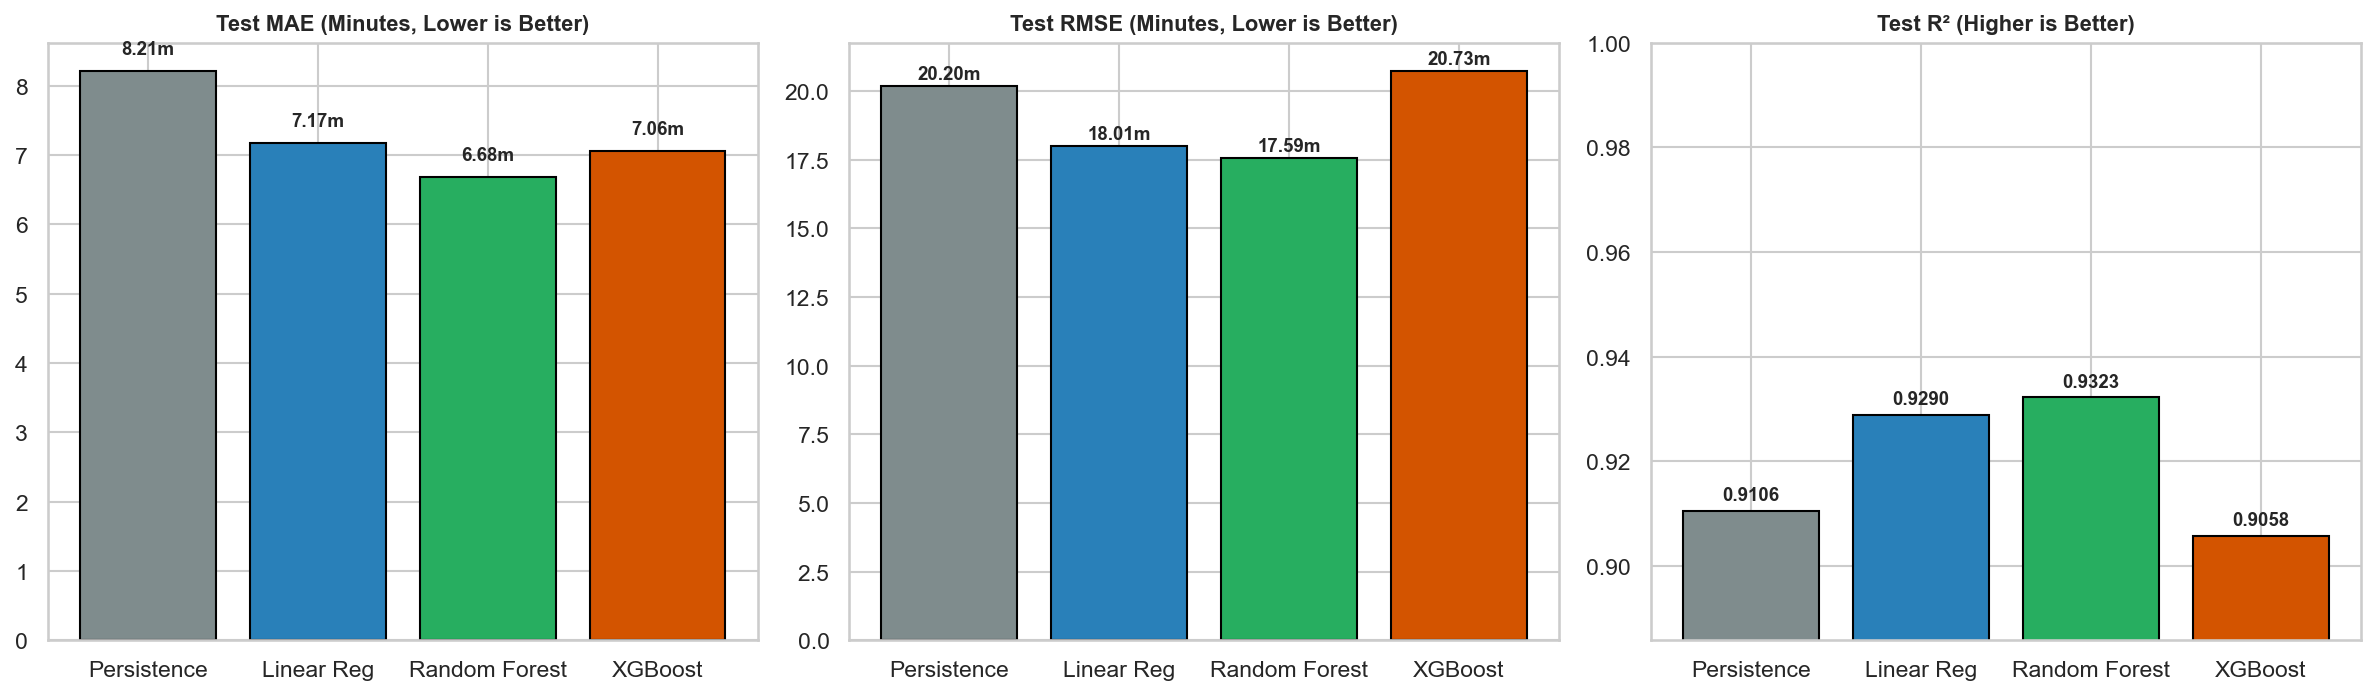

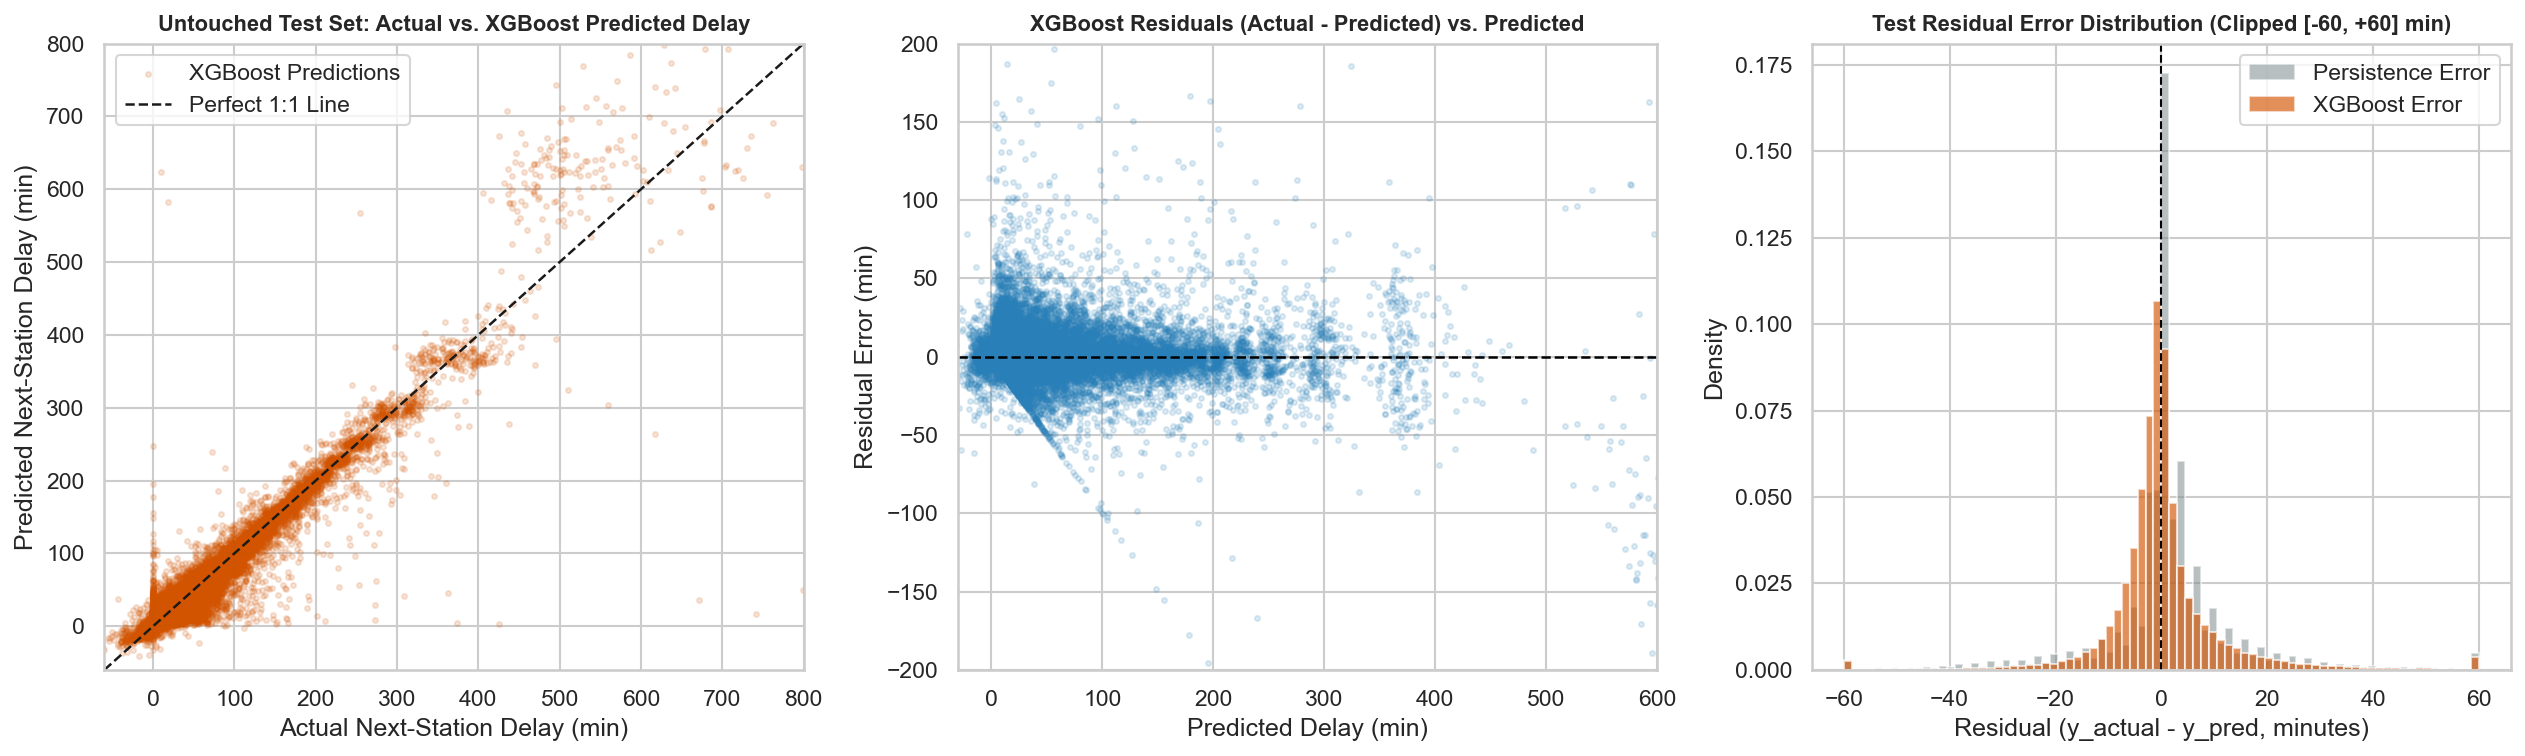

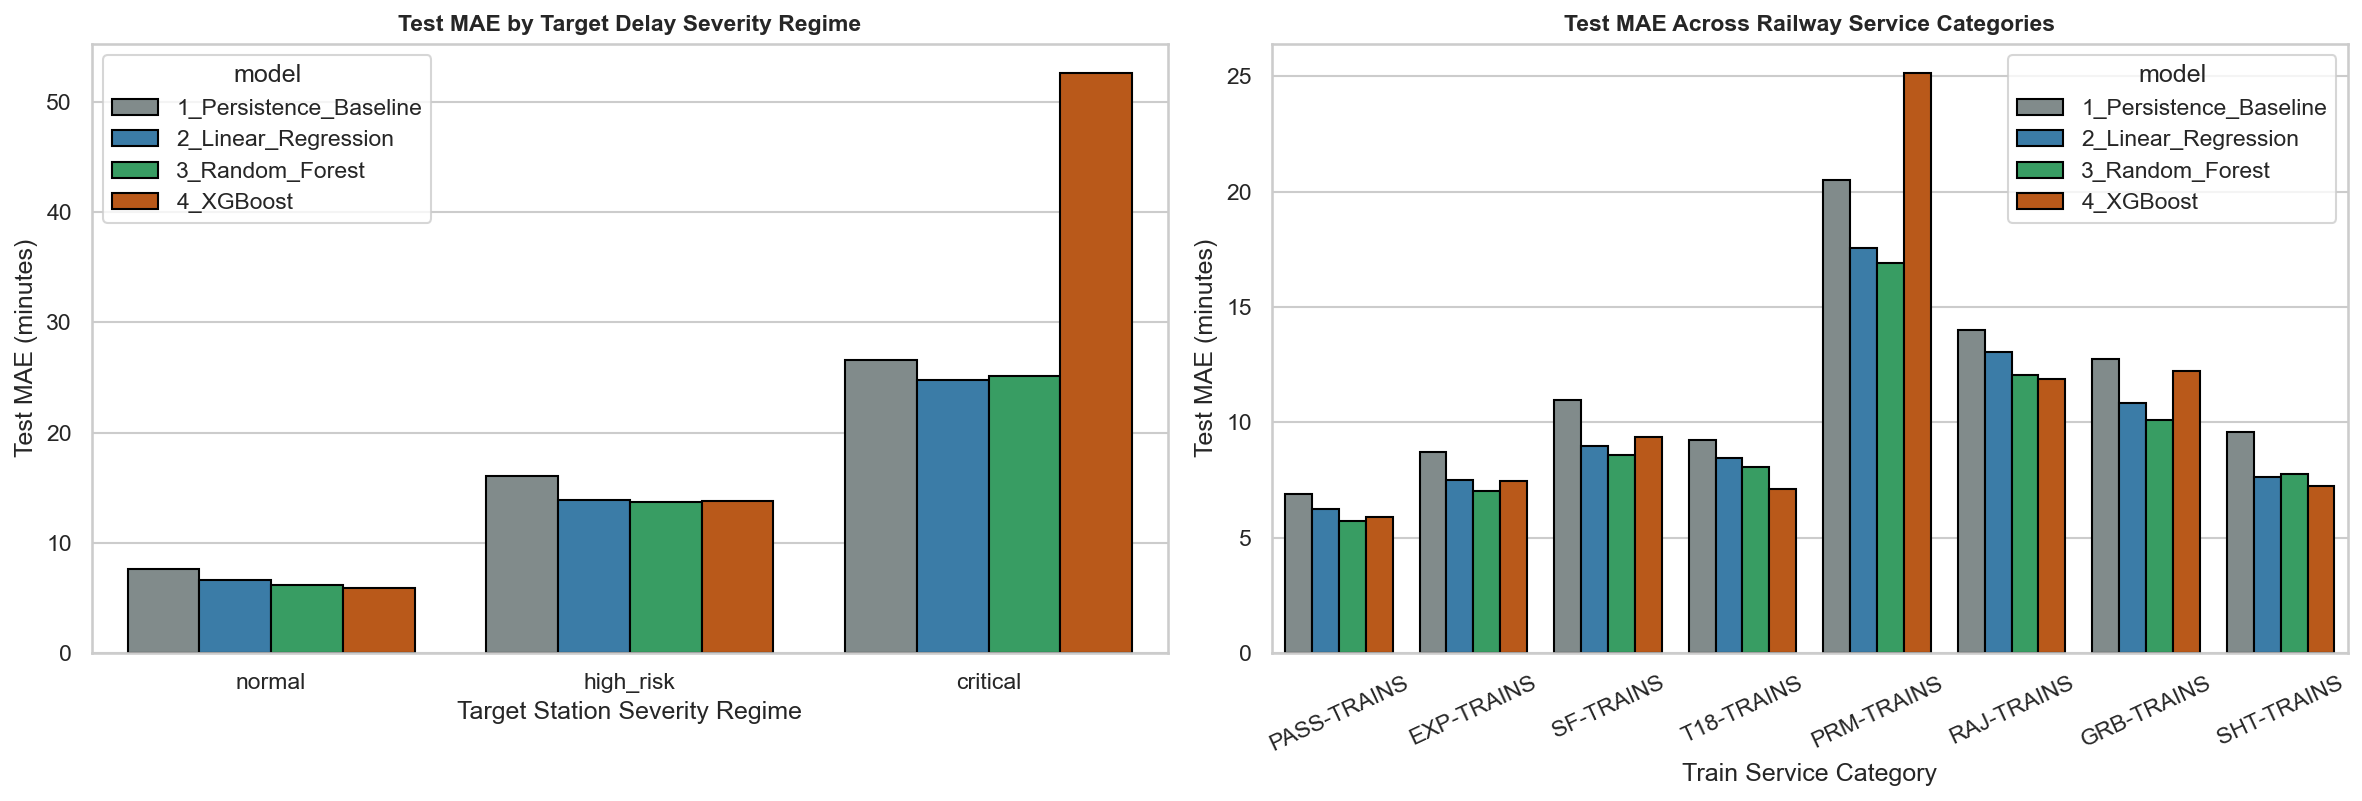

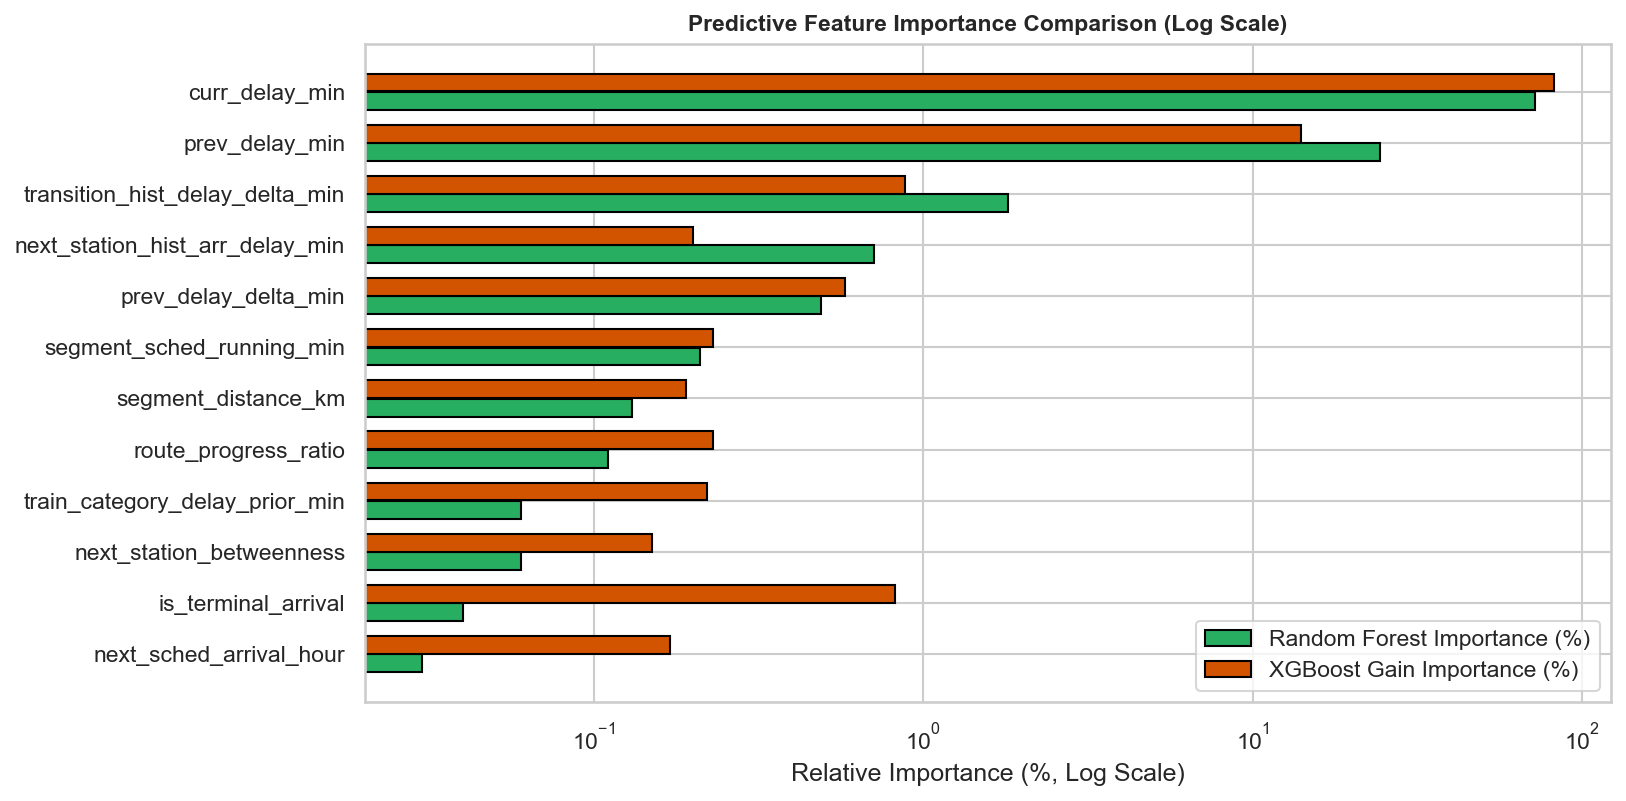

In [11]:
# Figure 1: Overall Test MAE, RMSE, and R² Comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
models_short = ["Persistence", "Linear Reg", "Random Forest", "XGBoost"]
palette = ["#7f8c8d", "#2980b9", "#27ae60", "#d35400"]

for ax, metric, title in zip(
    axes,
    ["test_MAE", "test_RMSE", "test_R2"],
    ["Test MAE (Minutes, Lower is Better)", "Test RMSE (Minutes, Lower is Better)", "Test R² (Higher is Better)"],
):
    vals = overall_comparison_df[metric].to_numpy()
    bars = ax.bar(models_short, vals, color=palette, edgecolor="black")
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    if metric == "test_R2":
        ax.set_ylim(min(vals) - 0.02, 1.0)
    for b, v in zip(bars, vals):
        fmt = f"{v:.4f}" if metric == "test_R2" else f"{v:.2f}m"
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + (0.002 if metric == "test_R2" else 0.25), fmt, ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "step04_03_model_comparison_mae_rmse_r2.png", dpi=150)
plt.show()

# Figure 2: Actual vs. Predicted & Residual Diagnostics (50,000 Stratified Test Sample for Scatter Clarity)
plot_idx = rng.choice(len(y_test), size=50_000, replace=False)
y_true_s = y_test[plot_idx]
y_persist_s = test_predictions["1_Persistence_Baseline"][plot_idx]
y_xgb_s     = test_predictions["4_XGBoost"][plot_idx]
res_persist = y_true_s - y_persist_s
res_xgb     = y_true_s - y_xgb_s

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

axes[0].scatter(y_true_s, y_xgb_s, alpha=0.15, s=6, color="#d35400", label="XGBoost Predictions")
axes[0].plot([-60, 1440], [-60, 1440], "k--", lw=1.2, label="Perfect 1:1 Line")
axes[0].set_xlim(-60, 800)
axes[0].set_ylim(-60, 800)
axes[0].set_title("Untouched Test Set: Actual vs. XGBoost Predicted Delay", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Actual Next-Station Delay (min)")
axes[0].set_ylabel("Predicted Next-Station Delay (min)")
axes[0].legend()

axes[1].scatter(y_xgb_s, res_xgb, alpha=0.15, s=6, color="#2980b9")
axes[1].axhline(0, color="black", linestyle="--", lw=1.2)
axes[1].set_xlim(-30, 600)
axes[1].set_ylim(-200, 200)
axes[1].set_title("XGBoost Residuals (Actual - Predicted) vs. Predicted", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("Predicted Delay (min)")
axes[1].set_ylabel("Residual Error (min)")

axes[2].hist(np.clip(res_persist, -60, 60), bins=80, alpha=0.55, label="Persistence Error", color="#7f8c8d", density=True)
axes[2].hist(np.clip(res_xgb, -60, 60), bins=80, alpha=0.65, label="XGBoost Error", color="#d35400", density=True)
axes[2].axvline(0, color="black", linestyle="--", lw=1.0)
axes[2].set_title("Test Residual Error Distribution (Clipped [-60, +60] min)", fontsize=10.5, fontweight="bold")
axes[2].set_xlabel("Residual (y_actual - y_pred, minutes)")
axes[2].set_ylabel("Density")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "step04_03_actual_vs_predicted_and_residuals.png", dpi=150)
plt.show()

# Figure 3: Stratified Test MAE Across Delay Severity & Service Categories
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.barplot(
    data=severity_perf_df,
    x="target_severity",
    y="MAE",
    hue="model",
    palette=palette,
    edgecolor="black",
    ax=axes[0],
)
axes[0].set_title("Test MAE by Target Delay Severity Regime", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Target Station Severity Regime")
axes[0].set_ylabel("Test MAE (minutes)")

sns.barplot(
    data=train_cat_perf_df,
    x="primary_type_code",
    y="MAE",
    hue="model",
    palette=palette,
    edgecolor="black",
    ax=axes[1],
)
axes[1].set_title("Test MAE Across Railway Service Categories", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Train Service Category")
axes[1].set_ylabel("Test MAE (minutes)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(FIG_DIR / "step04_03_performance_by_severity_and_train_type.png", dpi=150)
plt.show()

# Figure 4: Feature Importance Comparison (Random Forest vs. XGBoost)
fig, ax = plt.subplots(figsize=(11, 5.5))
fi_plot = feature_imp_df.sort_values("rf_importance_pct", ascending=True)
y_pos = np.arange(len(fi_plot))
ax.barh(y_pos - 0.18, fi_plot["rf_importance_pct"], height=0.35, label="Random Forest Importance (%)", color="#27ae60", edgecolor="black")
ax.barh(y_pos + 0.18, fi_plot["xgb_gain_importance_pct"], height=0.35, label="XGBoost Gain Importance (%)", color="#d35400", edgecolor="black")
ax.set_yticks(y_pos)
ax.set_yticklabels(fi_plot["feature_name"])
ax.set_xscale("log")
ax.set_xlabel("Relative Importance (%, Log Scale)")
ax.set_title("Predictive Feature Importance Comparison (Log Scale)", fontsize=11, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "step04_03_feature_importance_comparison.png", dpi=150)
plt.show()

In [12]:
# Compute residual tail diagnostics on the untouched Test set for the best model vs. Persistence
residual_diagnostics = {}
for m_key in ["1_Persistence_Baseline", "2_Linear_Regression", "3_Random_Forest", "4_XGBoost"]:
    abs_err = np.abs(y_test - test_predictions[m_key])
    residual_diagnostics[m_key] = {
        "pct_within_5m": round(float(np.mean(abs_err <= 5.0) * 100.0), 2),
        "pct_within_10m": round(float(np.mean(abs_err <= 10.0) * 100.0), 2),
        "pct_within_15m": round(float(np.mean(abs_err <= 15.0) * 100.0), 2),
        "p90_abs_error_min": round(float(np.quantile(abs_err, 0.90)), 2),
        "p95_abs_error_min": round(float(np.quantile(abs_err, 0.95)), 2),
        "p99_abs_error_min": round(float(np.quantile(abs_err, 0.99)), 2),
    }

findings_step04_03 = {
    "step": "step04_03_delay_prediction_models",
    "evaluation_scope": {
        "n_train_total": 26528080,
        "n_train_sample_linear_xgb": int(N_TRAIN_SAMPLE),
        "n_train_sample_rf": int(N_RF_SAMPLE),
        "n_val_evaluated_full": int(len(y_val)),
        "n_test_evaluated_full": int(len(y_test)),
    },
    "hyperparameter_tuning_log": tuning_df.to_dict(orient="records"),
    "overall_model_comparison": overall_comparison_df.to_dict(orient="records"),
    "test_residual_diagnostics": residual_diagnostics,
    "test_performance_by_severity": severity_perf_df.to_dict(orient="records"),
    "test_performance_by_stop_context": stop_type_perf_df.to_dict(orient="records"),
    "test_performance_by_train_category": train_cat_perf_df.to_dict(orient="records"),
    "feature_importance_comparison": feature_imp_df.to_dict(orient="records"),
}

findings_out_path = RESULT_DIR / "step04_03_MODEL_EVALUATION_FINDINGS.json"
with open(findings_out_path, "w", encoding="utf-8") as f:
    json.dump(findings_step04_03, f, indent=2)

print("=== STEP 4.3 MODEL EVALUATION & ARTIFACT EXPORT COMPLETE ===")
print(f"Saved findings to: {findings_out_path}")

=== STEP 4.3 MODEL EVALUATION & ARTIFACT EXPORT COMPLETE ===
Saved findings to: D:\M_Tech_CSE_AI\SEM01\DWDM\project\indian_railway_delay\results\step04_03_MODEL_EVALUATION_FINDINGS.json
